## Кластеризация

### KMeans

Задача кластеризация это задача разделения объектов на множества (кластеры), которые обладают следующим свойством - объекты внутри одного кластера должны быть "похожи" друг на друга, а объекты из разных кластеров должны "отличаться" друг от друга.

В неформальном определении кластера фигурируют слова <strong><i>похожи</i></strong> и <strong><i>непохожи</i></strong>. В понимании этих неформальных определений кроется ключ к построению различных алгоритмов кластеризации. Однако, так или иначе "похожесть" объектов тесно связана с расстоянием между этими объектами.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns
import scipy
import warnings
warnings.filterwarnings('ignore')

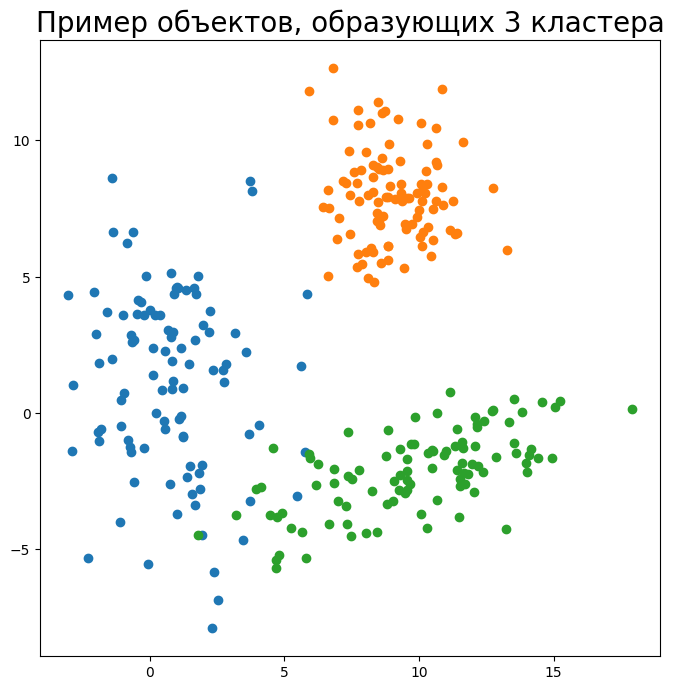

In [ ]:
x1 = np.random.multivariate_normal(mean=[1, 1], cov=np.array([[3, 0], [0, 10]]), size=100)
x2 = np.random.multivariate_normal(mean=[9, 8], cov=np.array([[2, 0], [0, 3]]), size=100)
x3 = np.random.multivariate_normal(mean=[10, -2], cov=np.array([[10, 3], [3, 2]]), size=100)
X = np.r_[x1, x2, x3]

plt.figure(figsize=(8, 8))
plt.scatter(x1[:, 0], x1[:, 1])
plt.scatter(x2[:, 0], x2[:, 1])
plt.scatter(x3[:, 0], x3[:, 1])
plt.title('Пример объектов, образующих 3 кластера', fontsize=20)
plt.show()

Одним из самых известных и старых алгоритмов кластеризации является [<font color='limegreen'>K-Means</font>](https://ru.wikipedia.org/wiki/Метод_k-средних) (Методы k средних). Рассмотрим пример его работы.

<b>Алгоритм KMeans</b>:

1) Случайно инициализируем центры k кластеров ($c_{i}, \ i = 1, \dots, k$)

2) Относим к классу i все объекты, которые ближе всего к i-ому центру ($c_{i}$)

3) Пересчитываем центры кластеров как $c_{i} = \frac{1}{|A_{i}|} \sum\limits_{x \in A_{i}}x \ $ (Где: $A_{i}$ - множество всех объектов, которые принадлежат к i-ому кластеру, $|A_{i}|$ - мощность этого множества) (По факту, $c_{i}$ - среднее значение координат точек i-ого кластера)

Шаги 2-3 повторяем до выполнения условия сходимости (например, когда центры кластеров перестанут сильно меняться).

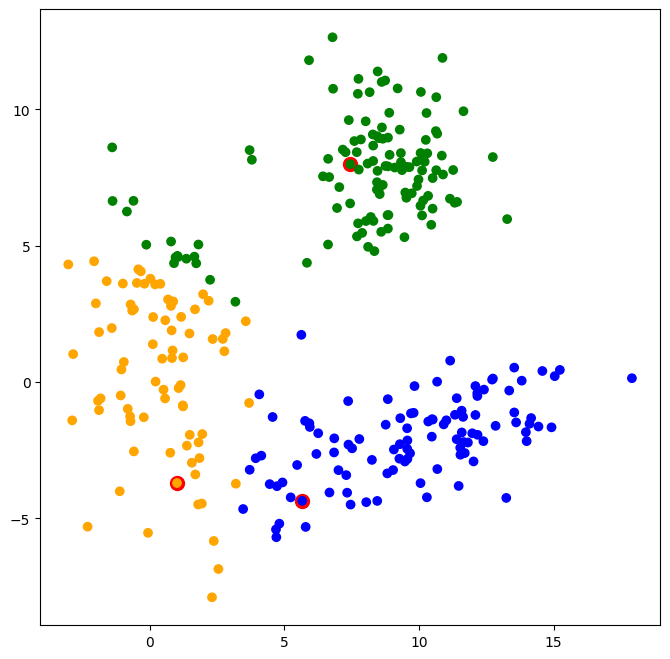

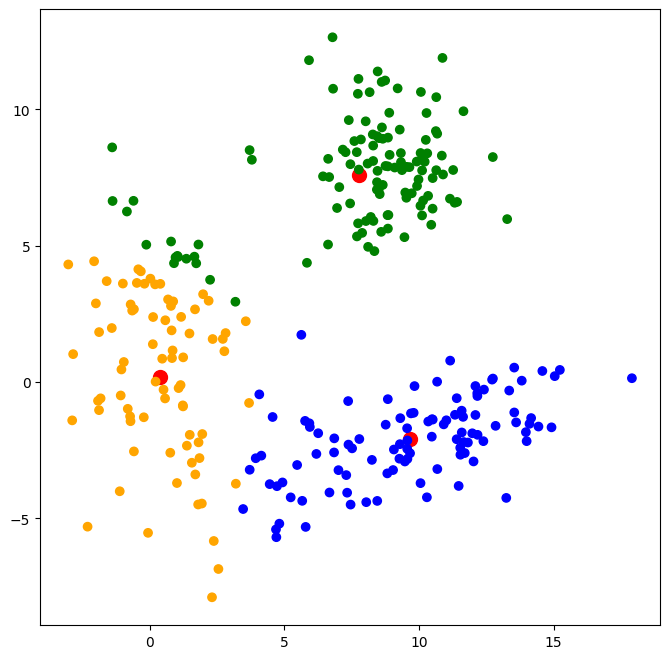

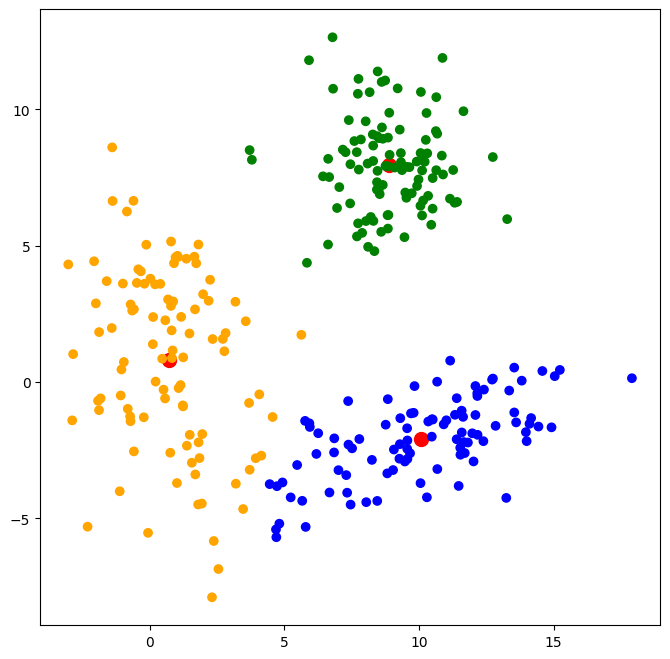

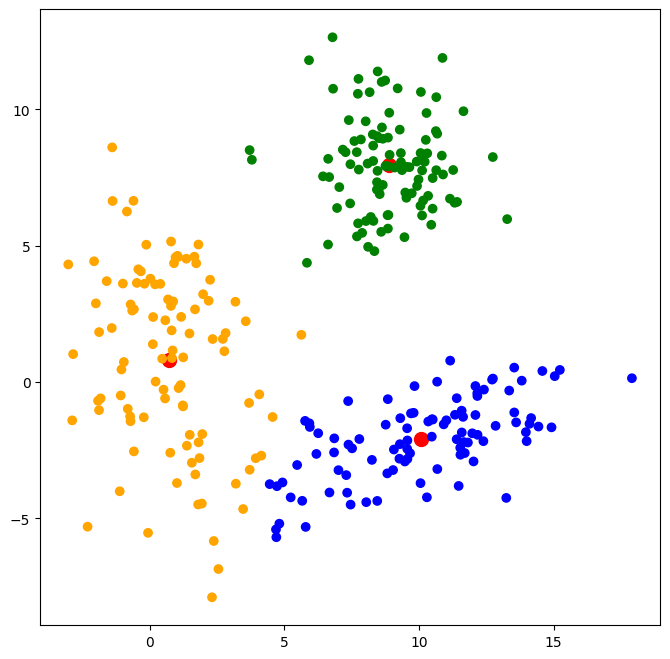

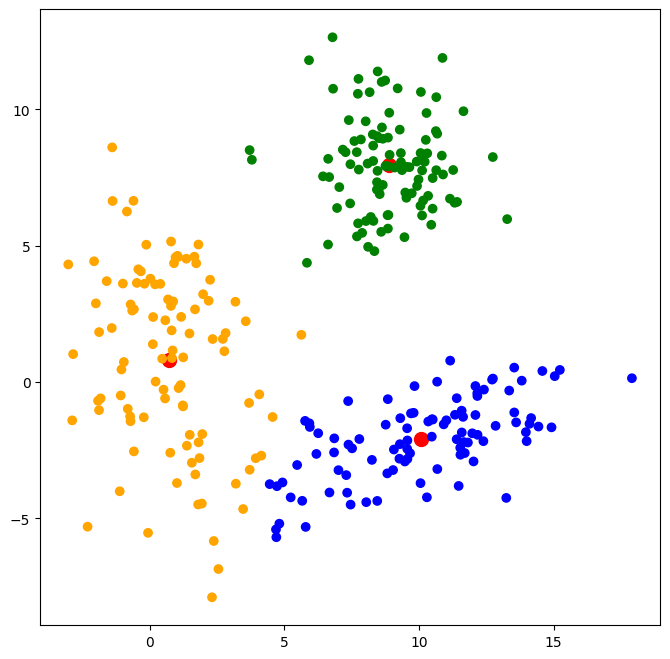

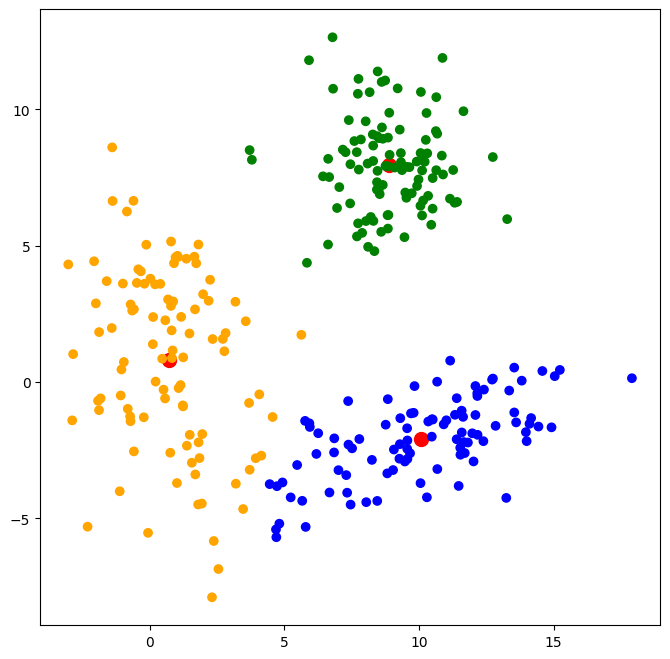

In [ ]:
cluster_centers = X[np.random.choice(np.arange(X.shape[0]), size=3)]
previous_centers = cluster_centers
centers_distance_change = []
cluster_labels = np.argsort(scipy.spatial.distance.cdist(cluster_centers, X), axis=0)[0]
plt.figure(figsize=(8, 8))
plt.scatter(cluster_centers[:, 0], cluster_centers[:, 1], color='red', s=100)
plt.scatter(X[:, 0], X[:, 1], c=np.array(['green', 'blue', 'orange'])[cluster_labels]);

for i in range(5):
    # отнесение объектов по кластерам
    cluster_labels = np.argsort(scipy.spatial.distance.cdist(cluster_centers, X), axis=0)[0]
    # пересчёт центров кластеров
    cluster_centers = []
    for j in range(3):
        cluster_centers.append(X[cluster_labels == j].mean(axis=0))
    cluster_centers = np.array(cluster_centers)
    centers_distance_change.append(((cluster_centers - previous_centers)**2).sum(axis=1).mean())
    previous_centers = cluster_centers
    plt.figure(figsize=(8, 8))
    plt.scatter(cluster_centers[:, 0], cluster_centers[:, 1], color='red', s=100)
    plt.scatter(X[:, 0], X[:, 1], c=np.array(['green', 'blue', 'orange'])[cluster_labels])

### Задача 18

Write a Python function that implements the k-Means algorithm for clustering, starting with specified initial centroids and a set number of iterations. The function should take a list of points (each represented as a tuple of coordinates), an integer k representing the number of clusters to form, a list of initial centroids (each a tuple of coordinates), and an integer representing the maximum number of iterations to perform. The function will iteratively assign each point to the nearest centroid and update the centroids based on the assignments until the centroids do not change significantly, or the maximum number of iterations is reached. The function should return a list of the final centroids of the clusters. Round to the nearest fourth decimal.

In [ ]:
import typing as t
import itertools

import numpy as np
from scipy.spatial.distance import cdist

In [ ]:
Point = t.Tuple[float, float]
AssignedPoints = t.List[t.Tuple[Point, int]]
Centroids = t.List[Point]

#### `assign_points_to_clusters`

Сопоставляем точки и ближайшие к ним центры кластеров

In [ ]:
points = [(0, 0), (1, 1), (5, 5)]
initial_centroids = [(0, 0), (6, 6)]

In [ ]:
XA = np.array(points)
XB = np.array(initial_centroids)
print(XA)
print(XB)

[[0 0]
 [1 1]
 [5 5]]
[[0 0]
 [6 6]]


In [ ]:
dist_matrix = cdist(XA, XB)
print(dist_matrix)

[[0.         8.48528137]
 [1.41421356 7.07106781]
 [7.07106781 1.41421356]]


In [ ]:
argmin_indices = np.argmin(dist_matrix, axis=1)
print(argmin_indices)

[0 0 1]


In [ ]:
assigned_points = [
    ((0, 0), 0),
    ((1, 1), 0),
    ((5, 5), 1)
]

In [ ]:
def assign_points_to_clusters(
    points: list[Point],
    centroids: Centroids
) -> AssignedPoints:
    dist_matrix = cdist(
        XA=np.array(points),
        XB=np.array(centroids)
    )
    argmin_indices = np.argmin(dist_matrix, axis=1)
    assigned_points = [
        (point, cluster_idx) for point, cluster_idx in zip(points, argmin_indices)
    ]
    return assigned_points

#### `recompute_clusters`

Обновляем центры кластеров

In [ ]:
assigned_points = [
    ((0, 0), 0),
    ((5, 5), 1),
    ((1, 1), 0)
]

In [ ]:
assigned_points.sort(key=lambda x: x[1])
print(assigned_points)

[((0, 0), 0), ((1, 1), 0), ((5, 5), 1)]


In [ ]:
for cluster_idx, group in itertools.groupby(assigned_points, key=lambda x: x[1]):
    print(f"Кластер №{cluster_idx}")
    print(list(group))

Кластер №0
[((0, 0), 0), ((1, 1), 0)]
Кластер №1
[((5, 5), 1)]


In [ ]:
coords = [(0, 0), (1, 1)]
print(np.mean(coords, axis=0))

[0.5 0.5]


In [ ]:
coords = [(5, 5)]
print(np.mean(coords, axis=0))

[5. 5.]


In [ ]:
new_centroids = [(0.5, 0.5), (5.0, 5.0)]

In [ ]:
def recompute_clusters(
    assigned_points: AssignedPoints,
) -> Centroids:
    assigned_points.sort(key=lambda x: x[1])
    new_clusters_centers = []
    for cluster_idx, group in itertools.groupby(
        assigned_points, key=lambda x: x[1]
    ):
        cluster_center = np.mean([coords for coords, _ in group], axis=0)
        new_clusters_centers.append(tuple(cluster_center))
    return new_clusters_centers

#### `k_means_clustering`

Объединяем `assign_points_to_clusters` и `recompute_clusters` в одну функцию

In [ ]:
points = [(0, 0), (1, 1), (5, 5)]
k = 2
initial_centroids = [(0, 0), (6, 6)]
max_iterations = 10

In [ ]:
def k_means_clustering(
    points: list[tuple[float, float]],
    k: int,
    initial_centroids: Centroids,
    max_iterations: int
) -> Centroids:
    current_centroids = initial_centroids
    for _ in range(max_iterations):
        assigned_points = assign_points_to_clusters(
            points=points,
            centroids=current_centroids
        )
        current_centroids = recompute_clusters(
            assigned_points=assigned_points,
        )
    final_centroids = current_centroids
    return final_centroids

In [ ]:
final_centroids = k_means_clustering(points, k, initial_centroids, max_iterations)
print(final_centroids)

[(np.float64(0.5), np.float64(0.5)), (np.float64(5.0), np.float64(5.0))]


#### Как задать класс `KMeans`?

In [ ]:
class CustomKMeans:
    def __init__(self, k: int, max_iterations: int = 100):
        """
        Инициализируем объект класса `KMeans` -- наш алгоритм кластеризации
        Parameters:
        - k: кол-во кластеров
        - max_iterations: максимальное кол-во итераций
        """
        self.k = k
        self.max_iterations = max_iterations

        self.centroids_: t.Optional[Centroids] = None
        self.labels_: t.Optional[t.List[int]] = None
        self.n_iter_: int = 0

    def _assign_points_to_clusters(self, points: t.List[Point]) -> t.List[int]:
        """Сопоставляем точки и ближайшие к ним центры кластеров"""
        dist_matrix = cdist(
            XA=np.array(points),
            XB=np.array(self.centroids_)
        )
        return np.argmin(dist_matrix, axis=1).tolist()

    def _recompute_centroids(self, points: t.List[Point], labels: t.List[int]) -> Centroids:
        """Обновляем центры кластеров"""
        paired = sorted(zip(points, labels), key=lambda x: x[1])
        new_centroids = []
        for cluster_id, group in itertools.groupby(paired, key=lambda x: x[1]):
            coords = [p for p, _ in group]
            mean_point = np.mean(coords, axis=0)
            new_centroids.append(tuple(mean_point))
        return new_centroids

    def fit(self, points: t.List[Point], initial_centroids: Centroids) -> "CustomKMeans":
        """
        'Обучаем' наш алгоритм кластеризации -- совершаем `max_iterations` итераций для поиска оптимальных центров
        Parameters:
        - points: список точек в формате (x, y)
        - initial_centroids: исходные центры кластеров (ровно `k` штук)
        Returns:
        - self
        """
        if len(initial_centroids) != self.k:
            raise ValueError(f"Должно быть ровно {self.k} исходных центров, но получили {len(initial_centroids)}")

        self.centroids_ = initial_centroids
        self.labels_ = None

        for iteration in range(self.max_iterations):
            self.labels_ = self._assign_points_to_clusters(points)
            new_centroids = self._recompute_centroids(points, self.labels_)
            # здесь можно добавить критерий останова
            self.centroids_ = new_centroids

        self.centroids_ = [
            (round(x, 4), round(y, 4)) for (x, y) in self.centroids_
        ]

        self.n_iter_ = self.max_iterations
        return self

    def predict(self, points: t.List[Point]) -> t.List[int]:
        """Получаем распределение по кластерам для новых точек"""
        if self.centroids_ is None:
            raise ValueError("Модель 'не обучена', сначала нужно запустить метод `.fit()`")
        return self._assign_points_to_clusters(points)

In [ ]:
points = [(0, 0), (1, 1), (5, 5)]
k = 2
initial_centroids = [(0, 0), (6, 6)]
max_iterations = 10

In [ ]:
kmeans = CustomKMeans(k=k, max_iterations=max_iterations)
kmeans.fit(points, initial_centroids=initial_centroids)
print(f"Итоговые центры кластеров: {kmeans.centroids_}")

Итоговые центры кластеров: [(np.float64(0.5), np.float64(0.5)), (np.float64(5.0), np.float64(5.0))]


In [ ]:
new_points = [(0.9, 0.9), (5.1, 5.1)]
print(f"Предсказания для новых точек: {kmeans.predict(new_points)}")

Предсказания для новых точек: [0, 1]


### Задача 3

Для набора данных $  \{ [2,2],[4,2],[3,3],[8,5],[10,5],[9,6],[15,1],[17,1],[16,2]			\}		$ реализовать алгоритм $k-means$ с параметром $k = 3$ из изначального приближения: $\{   [12,3],[8,2],[13,3]   \}$.

Посчитать среднее значение внутрикластерного расстояния, межкластерного расстояния, индекс Данна

[ссылка на лекцию Соколова](https://github.com/esokolov/ml-course-hse/blob/master/2017-fall/lecture-notes/lecture12-unsupervised.pdf)

Индекс Данна:
$$ \frac{\min\limits_{1 \le i < j \le k} \quad d (k,~k')}{\max\limits_{1 \le l \le k} \quad d(k)} $$

$d(k)$ - внутрикластерное расстояние

$d(k,~k')$ - расстояние между центрами двух кластеров

In [ ]:
points = [
    (2, 2), (4, 2), (3, 3),
    (8, 5), (10, 5), (9, 6),
    (15, 1), (17, 1), (16, 2)
]

initial_centroids = [
    (12, 3), (8, 2), (13, 3)
]

k = 3
max_iterations = 100

In [ ]:
final_centroids = k_means_clustering(
    points=points,
    k=k,
    initial_centroids=initial_centroids,
    max_iterations=max_iterations
)

In [ ]:
for i, centroid in enumerate(final_centroids, 1):
    print(f"Кластер №{i}: ({centroid[0]:.2f}, {centroid[1]:.2f})")

Кластер №1: (9.00, 5.33)
Кластер №2: (3.00, 2.33)
Кластер №3: (16.00, 1.33)


In [ ]:
final_assignments = assign_points_to_clusters(points, final_centroids)
cluster_ids = [cid for _, cid in final_assignments]
points_array = np.array(points)
final_centroids_array = np.array(final_centroids)
initial_centroids_array = np.array(initial_centroids)

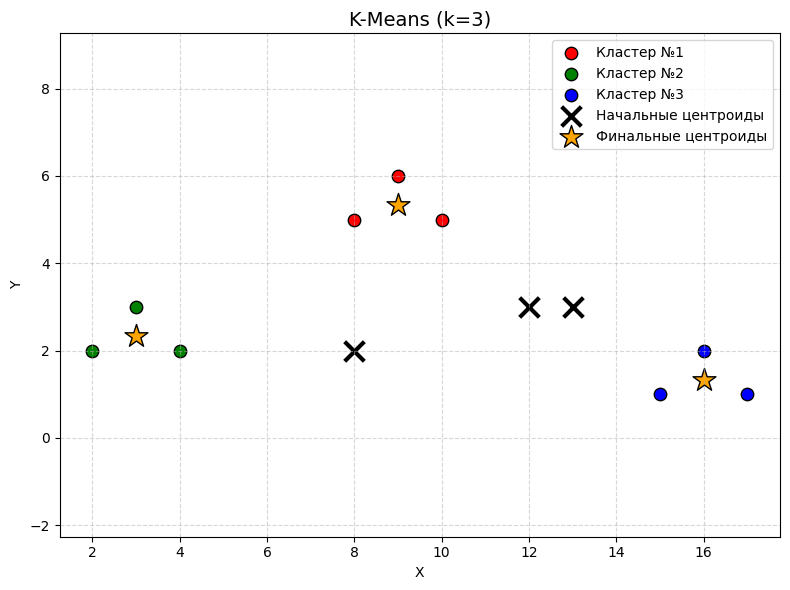

In [ ]:
plt.figure(figsize=(8, 6))

colors = ['red', 'green', 'blue']
for i in range(k):
    cluster_points = points_array[np.array(cluster_ids) == i]
    plt.scatter(
        cluster_points[:, 0],
        cluster_points[:, 1],
        c=colors[i],
        label=f'Кластер №{i+1}',
        s=80,
        edgecolor='k'
    )

plt.scatter(
    initial_centroids_array[:, 0],
    initial_centroids_array[:, 1],
    c='black',
    marker='x',
    s=200,
    linewidths=3,
    label='Начальные центроиды'
)

plt.scatter(
    final_centroids_array[:, 0],
    final_centroids_array[:, 1],
    c='orange',
    marker='*',
    s=300,
    edgecolor='k',
    linewidths=1,
    label='Финальные центроиды'
)

plt.title('K-Means (k=3)', fontsize=14)
plt.xlabel('X')
plt.ylabel('Y')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.axis('equal')
plt.tight_layout()
plt.show()

### DBSCAN

#### Простой пример

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import DBSCAN
from sklearn.datasets import make_moons

In [ ]:
X, _ = make_moons(n_samples=300, noise=0.05, random_state=42)

In [ ]:
dbscan = DBSCAN(eps=0.3, min_samples=5)
labels = dbscan.fit_predict(X)

In [ ]:
unique_labels = np.unique(labels)
colors = plt.cm.tab10(np.linspace(0, 1, len(unique_labels)))

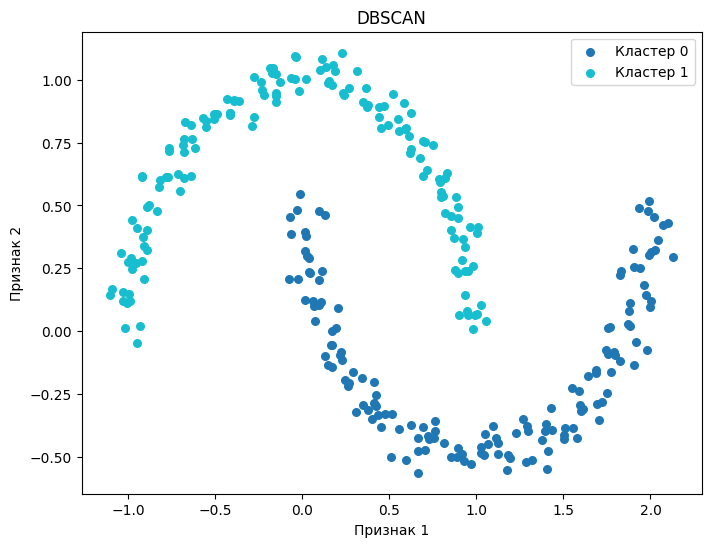

In [ ]:
plt.figure(figsize=(8, 6))
for k, col in zip(unique_labels, colors):
    if k == -1:
        col = [0, 0, 0, 1]
    class_member_mask = (labels == k)
    plt.scatter(X[class_member_mask, 0], X[class_member_mask, 1],
                c=[col], label=f'Кластер {k}' if k != -1 else 'Шум', s=30)

plt.legend()
plt.title("DBSCAN")
plt.xlabel("Признак 1")
plt.ylabel("Признак 2")
plt.show()

#### Реальные данные

In [144]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN
from sklearn.decomposition import PCA

In [145]:
data = load_wine()
X = data.data
y_true = data.target

In [146]:
X_scaled = StandardScaler().fit_transform(X)

In [147]:
# print(data.DESCR)

In [148]:
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)

In [149]:
eps=0.5
min_samples=5
dbscan = DBSCAN(eps=eps, min_samples=min_samples)
y_pred = dbscan.fit_predict(X_pca)

In [150]:
display(y_pred)

array([ 0,  0,  0, -1,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0, -1,  0,  0,
        0, -1,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,
        0,  0,  0,  0,  0,  0,  0,  0,  0, -1,  0, -1,  0,  0,  0,  0, -1,
        0,  0,  0,  0,  0,  0,  0,  0,  2,  1,  1, -1, -1,  2,  0, -1,  2,
       -1,  0,  1,  0, -1,  0,  0,  2,  2,  1,  0, -1, -1,  0,  2,  3,  0,
        2,  2,  2,  1,  2,  1,  1,  1,  2,  2,  0, -1,  2,  0,  2,  2,  2,
       -1,  2,  2,  1,  2,  1,  2,  0,  0,  2,  1,  2,  2, -1,  2,  2, -1,
        2,  0,  0,  1, -1,  0,  2, -1,  1,  2,  1, -1,  3,  3,  3,  3,  3,
       -1,  3,  3,  3,  3,  3,  3,  3, -1,  3, -1,  3,  4,  4,  4,  4, -1,
        4,  3, -1,  4,  3, -1, -1,  3, -1,  3,  3,  4,  3,  4,  4,  4,  4,
       -1,  3,  4, -1,  4,  4,  4, -1])

In [151]:
unique_labels = np.unique(y_pred)
label_to_index = {label: idx for idx, label in enumerate(unique_labels)}
y_pred_indexed = np.array([label_to_index[label] for label in y_pred])

colors = []
for label in unique_labels:
    if label == -1:
        colors.append('black')
    else:
        colors.append(plt.cm.tab10(label % 10))

from matplotlib.colors import ListedColormap
cmap = ListedColormap(colors)

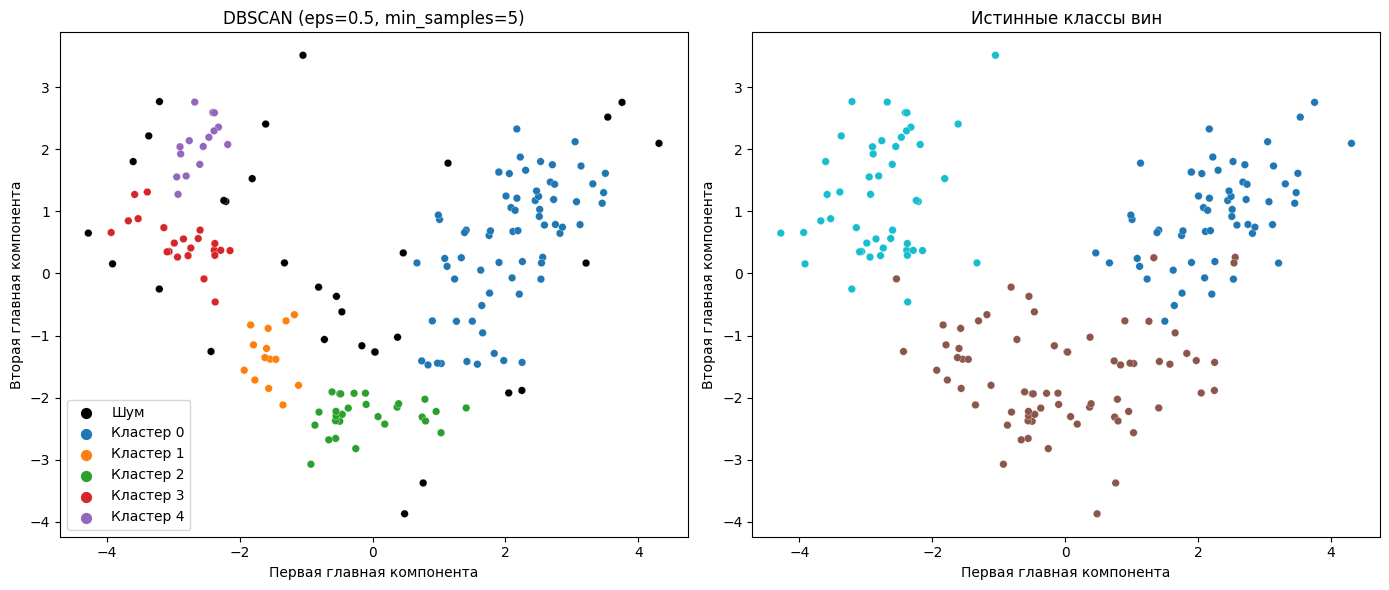

In [152]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

scatter1 = axes[0].scatter(
    X_pca[:, 0], X_pca[:, 1],
    c=y_pred_indexed,
    cmap=cmap,
    s=30,
    edgecolors='w',
    linewidth=0.2
)
axes[0].set_title(f"DBSCAN (eps={eps}, min_samples={min_samples})")
axes[0].set_xlabel("Первая главная компонента")
axes[0].set_ylabel("Вторая главная компонента")

for label, color in zip(unique_labels, colors):
    name = 'Шум' if label == -1 else f'Кластер {label}'
    axes[0].scatter([], [], c=[color], label=name, s=50)
axes[0].legend()

axes[1].scatter(X_pca[:, 0], X_pca[:, 1], c=y_true, cmap='tab10', s=30, edgecolors='w', linewidth=0.2)
axes[1].set_title("Истинные классы вин")
axes[1].set_xlabel("Первая главная компонента")
axes[1].set_ylabel("Вторая главная компонента")

plt.tight_layout()
plt.show()

In [153]:
n_clusters = len(set(y_pred)) - (1 if -1 in y_pred else 0)
n_noise = list(y_pred).count(-1)
print(f"Найдено кластеров: {n_clusters}")
print(f"Шумовых точек: {n_noise}")
print(f"Всего точек: {len(y_pred)}")

Найдено кластеров: 5
Шумовых точек: 31
Всего точек: 178


In [159]:
from sklearn.neighbors import NearestNeighbors
k = min_samples-1
nbrs = NearestNeighbors(n_neighbors=k+1, algorithm='auto').fit(X_pca)
distances, indices = nbrs.kneighbors(X_pca)

k_distances = distances[:, k]
k_distances_sorted = np.sort(k_distances)[::-1]

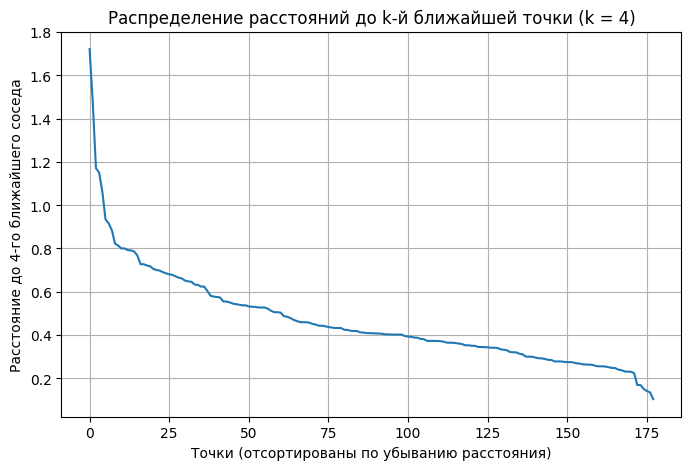

In [162]:
plt.figure(figsize=(8, 5))
plt.plot(range(len(k_distances_sorted)), k_distances_sorted, linewidth=1.5)
plt.title(f'Распределение расстояний до k-й ближайшей точки (k = {k})')
plt.xlabel('Точки (отсортированы по убыванию расстояния)')
plt.ylabel(f'Расстояние до {k}-го ближайшего соседа')
plt.grid(True)
plt.show()

Выбираем `eps` в районе 'локтя', когда график начинает загибаться

#### sklearn example

In [ ]:
from sklearn.datasets import make_blobs
from sklearn.preprocessing import StandardScaler

centers = [[1, 1], [-1, -1], [1, -1]]
X, labels_true = make_blobs(
    n_samples=750, centers=centers, cluster_std=0.4, random_state=0
)

X = StandardScaler().fit_transform(X)

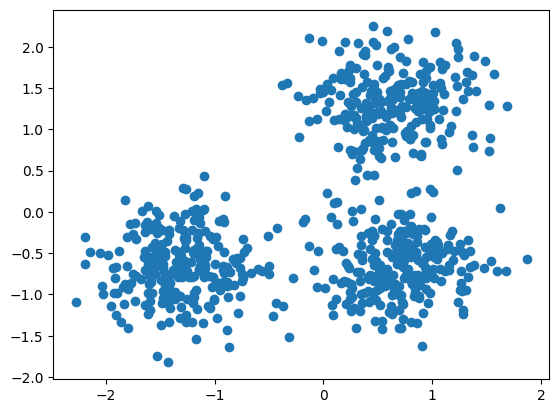

In [ ]:
import matplotlib.pyplot as plt

plt.scatter(X[:, 0], X[:, 1])
plt.show()

In [ ]:
import numpy as np

from sklearn import metrics
from sklearn.cluster import DBSCAN

db = DBSCAN(eps=0.3, min_samples=10).fit(X)
labels = db.labels_

# Number of clusters in labels, ignoring noise if present.
n_clusters_ = len(set(labels)) - (1 if -1 in labels else 0)
n_noise_ = list(labels).count(-1)

print("Estimated number of clusters: %d" % n_clusters_)
print("Estimated number of noise points: %d" % n_noise_)

Estimated number of clusters: 3
Estimated number of noise points: 18


In [ ]:
print(f"Homogeneity: {metrics.homogeneity_score(labels_true, labels):.3f}")
print(f"Completeness: {metrics.completeness_score(labels_true, labels):.3f}")
print(f"V-measure: {metrics.v_measure_score(labels_true, labels):.3f}")
print(f"Adjusted Rand Index: {metrics.adjusted_rand_score(labels_true, labels):.3f}")
print(
    "Adjusted Mutual Information:"
    f" {metrics.adjusted_mutual_info_score(labels_true, labels):.3f}"
)
print(f"Silhouette Coefficient: {metrics.silhouette_score(X, labels):.3f}")

Homogeneity: 0.953
Completeness: 0.883
V-measure: 0.917
Adjusted Rand Index: 0.952
Adjusted Mutual Information: 0.916
Silhouette Coefficient: 0.626


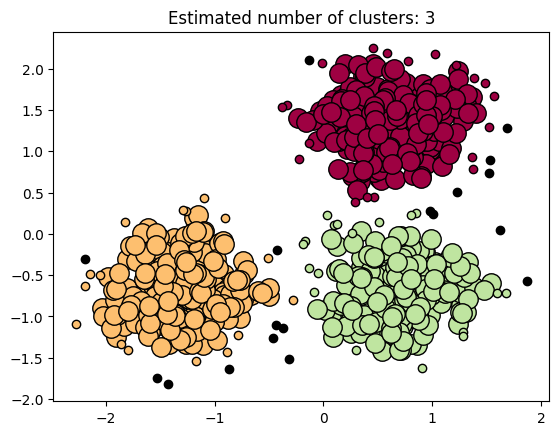

In [ ]:
unique_labels = set(labels)
core_samples_mask = np.zeros_like(labels, dtype=bool)
core_samples_mask[db.core_sample_indices_] = True

colors = [plt.cm.Spectral(each) for each in np.linspace(0, 1, len(unique_labels))]
for k, col in zip(unique_labels, colors):
    if k == -1:
        # Black used for noise.
        col = [0, 0, 0, 1]

    class_member_mask = labels == k

    xy = X[class_member_mask & core_samples_mask]
    plt.plot(
        xy[:, 0],
        xy[:, 1],
        "o",
        markerfacecolor=tuple(col),
        markeredgecolor="k",
        markersize=14,
    )

    xy = X[class_member_mask & ~core_samples_mask]
    plt.plot(
        xy[:, 0],
        xy[:, 1],
        "o",
        markerfacecolor=tuple(col),
        markeredgecolor="k",
        markersize=6,
    )

plt.title(f"Estimated number of clusters: {n_clusters_}")
plt.show()

### KMeans и рукописные цифры

In [ ]:
import numpy as np

from sklearn.datasets import load_digits

data, labels = load_digits(return_X_y=True)
(n_samples, n_features), n_digits = data.shape, np.unique(labels).size

print(f"# digits: {n_digits}; # samples: {n_samples}; # features {n_features}")

# digits: 10; # samples: 1797; # features 64


In [ ]:
display(data)
print(data.shape)

array([[ 0.,  0.,  5., ...,  0.,  0.,  0.],
       [ 0.,  0.,  0., ..., 10.,  0.,  0.],
       [ 0.,  0.,  0., ..., 16.,  9.,  0.],
       ...,
       [ 0.,  0.,  1., ...,  6.,  0.,  0.],
       [ 0.,  0.,  2., ..., 12.,  0.,  0.],
       [ 0.,  0., 10., ..., 12.,  1.,  0.]])

(1797, 64)


In [ ]:
from time import time

from sklearn import metrics
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler


def bench_k_means(kmeans, name, data, labels):
    """Benchmark to evaluate the KMeans initialization methods.

    Parameters
    ----------
    kmeans : KMeans instance
        A :class:`~sklearn.cluster.KMeans` instance with the initialization
        already set.
    name : str
        Name given to the strategy. It will be used to show the results in a
        table.
    data : ndarray of shape (n_samples, n_features)
        The data to cluster.
    labels : ndarray of shape (n_samples,)
        The labels used to compute the clustering metrics which requires some
        supervision.
    """
    t0 = time()
    estimator = make_pipeline(StandardScaler(), kmeans).fit(data)
    fit_time = time() - t0
    results = [name, fit_time, estimator[-1].inertia_]

    # Define the metrics which require only the true labels and estimator
    # labels
    clustering_metrics = [
        metrics.homogeneity_score,
        metrics.completeness_score,
        metrics.v_measure_score,
        metrics.adjusted_rand_score,
        metrics.adjusted_mutual_info_score,
    ]
    results += [m(labels, estimator[-1].labels_) for m in clustering_metrics]

    # The silhouette score requires the full dataset
    results += [
        metrics.silhouette_score(
            data,
            estimator[-1].labels_,
            metric="euclidean",
            sample_size=300,
        )
    ]

    # Show the results
    formatter_result = (
        "{:9s}\t{:.3f}s\t{:.0f}\t{:.3f}\t{:.3f}\t{:.3f}\t{:.3f}\t{:.3f}\t{:.3f}"
    )
    print(formatter_result.format(*results))

In [ ]:
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

print(82 * "_")
print("init\t\ttime\tinertia\thomo\tcompl\tv-meas\tARI\tAMI\tsilhouette")

kmeans = KMeans(init="k-means++", n_clusters=n_digits, n_init=4, random_state=0)
bench_k_means(kmeans=kmeans, name="k-means++", data=data, labels=labels)

kmeans = KMeans(init="random", n_clusters=n_digits, n_init=4, random_state=0)
bench_k_means(kmeans=kmeans, name="random", data=data, labels=labels)

pca = PCA(n_components=n_digits).fit(data)
kmeans = KMeans(init=pca.components_, n_clusters=n_digits, n_init=1)
bench_k_means(kmeans=kmeans, name="PCA-based", data=data, labels=labels)

print(82 * "_")

__________________________________________________________________________________
init		time	inertia	homo	compl	v-meas	ARI	AMI	silhouette
k-means++	0.273s	69545	0.598	0.645	0.621	0.469	0.617	0.155
random   	0.281s	69735	0.681	0.723	0.701	0.574	0.698	0.179
PCA-based	0.118s	69513	0.600	0.647	0.622	0.468	0.618	0.141
__________________________________________________________________________________


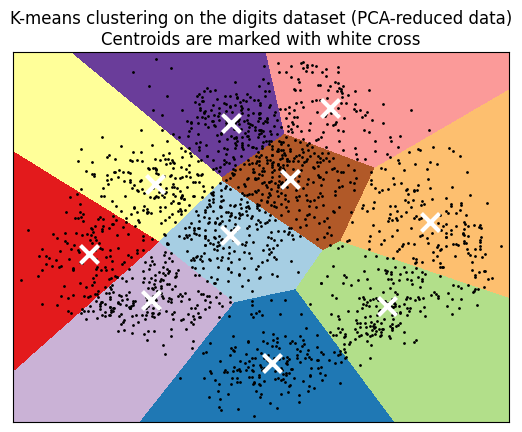

In [ ]:
import matplotlib.pyplot as plt

reduced_data = PCA(n_components=2).fit_transform(data)
kmeans = KMeans(init="k-means++", n_clusters=n_digits, n_init=4)
kmeans.fit(reduced_data)

# Step size of the mesh. Decrease to increase the quality of the VQ.
h = 0.02  # point in the mesh [x_min, x_max]x[y_min, y_max].

# Plot the decision boundary. For that, we will assign a color to each
x_min, x_max = reduced_data[:, 0].min() - 1, reduced_data[:, 0].max() + 1
y_min, y_max = reduced_data[:, 1].min() - 1, reduced_data[:, 1].max() + 1
xx, yy = np.meshgrid(np.arange(x_min, x_max, h), np.arange(y_min, y_max, h))

# Obtain labels for each point in mesh. Use last trained model.
Z = kmeans.predict(np.c_[xx.ravel(), yy.ravel()])

# Put the result into a color plot
Z = Z.reshape(xx.shape)
plt.figure(1)
plt.clf()
plt.imshow(
    Z,
    interpolation="nearest",
    extent=(xx.min(), xx.max(), yy.min(), yy.max()),
    cmap=plt.cm.Paired,
    aspect="auto",
    origin="lower",
)

plt.plot(reduced_data[:, 0], reduced_data[:, 1], "k.", markersize=2)
# Plot the centroids as a white X
centroids = kmeans.cluster_centers_
plt.scatter(
    centroids[:, 0],
    centroids[:, 1],
    marker="x",
    s=169,
    linewidths=3,
    color="w",
    zorder=10,
)
plt.title(
    "K-means clustering on the digits dataset (PCA-reduced data)\n"
    "Centroids are marked with white cross"
)
plt.xlim(x_min, x_max)
plt.ylim(y_min, y_max)
plt.xticks(())
plt.yticks(())
plt.show()